# GSI model results and analyses

This notebook reproduces the main analyses and figures presented in From Isolated to Cascading Green Stormwater Infrastructure: Effects of Configuration and Parameter Variability in Combined Sewer Systems.

Analyses include runoff and CSO reductions, variance decomposition, design-parameter sensitivity using partial rank correlation coefficients (PRCCs), loading-ratio sensitivity, and GSI implementation distributions.

The notebook uses SWMM simulation results. Input file descriptions, data structures, and units are documented in the accompanying README.md. Run the notebook sequentially with the required input files in the data/ directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import ScalarFormatter
from scipy.stats import rankdata

# Change these paths if the processed data are stored elsewhere.
DATA_DIR = Path('data')
# realted labels and formats for analyses and plots
CONFIGURATIONS = ('Isolated', 'Single-cascade', 'Two-cascade')
DENSITY_LEVELS = (25, 50, 75)
return_periods_all = [1, 2, 5, 10, 25, 50]
storm_labels = [f'{year}-Y' for year in return_periods_all]
storm_x = np.arange(len(return_periods_all))
scenario_idx = {
    (configuration, density): i * len(DENSITY_LEVELS) + j
    for i, configuration in enumerate(CONFIGURATIONS)
    for j, density in enumerate(DENSITY_LEVELS)
}

scenario_75 = [scenario_idx[config, 75] for config in CONFIGURATIONS]
CONFIGURATION_COLORS = {'Isolated': '0.78', 'Single-cascade': '#8FAECC',
                        'Two-cascade': '#D98C8C'}
GSI_COLORS = {'GR': '#c2a5cf', 'RG': '#92c5de', 'RB': '#e0e0e0'}
GSI_TYPES = ('GR', 'RG', 'RB')
LAND_USES = ('Urban', 'Open space', 'Residential')
LOADING_RATIOS = (1, 3, 5)
share_cols = ['design_share_total', 'parameter_share_total', 'dependence_share_total']
component_labels = ['Cascading-configuration effect', 'Parameter-variability effect',
                    'Configuration–parameter interaction']
component_colors = ['#D98C8C', '#8FAECC', '0.72']
markers = ['o', 's', '^']

### 1. Subcatchment runoff reduction analyses

The runoff array is ordered by storm, scenario, Monte Carlo realization, and subcatchment position. The nine scenarios are grouped by configuration (isolated, single-cascade, two-cascade), with densities of 25%, 50%, and 75% within each configuration. 

### 1.1. Runoff reduction 

In [2]:
# load runoff simualtion results
with np.load(DATA_DIR / 'run_reduction.npz') as data:
    all_percent_reduction = data['percent_reduction']

with np.load(DATA_DIR / 'index.npz') as data:
    urban_idx = data['urban_idx']
    resi_idx = data['resi_idx']
    green_idx = data['green_idx']

# Use integer positions throughout
node_indices = []
for indices in (urban_idx, resi_idx, green_idx):
    if indices.dtype == bool:
        indices = np.flatnonzero(indices)
    node_indices.append(indices.astype(int))
urban_idx, resi_idx, green_idx = node_indices

# Runoff and PRCC comparisons use the same land-use groups and configurations.
pair_specs = [
    {'panel': 'Urban: GR-RG vs Isolated', 'title': 'Urban (single-cascade)',
     'landuse': 'Urban', 'node_idx': urban_idx, 'configs': ('Isolated', 'Single-cascade')},
    {'panel': 'Residential: GR-RG vs Isolated', 'title': 'Residential (single-cascade)',
     'landuse': 'Residential', 'node_idx': resi_idx, 'configs': ('Isolated', 'Single-cascade')},
    {'panel': 'Residential: Two-cascade vs Isolated', 'title': 'Residential (two-cascade)',
     'landuse': 'Residential', 'node_idx': resi_idx, 'configs': ('Isolated', 'Two-cascade')},
]

In [3]:
# main runoff analyses (2-, 5-, and 50-year storms; 25% and 75% densities)
return_periods_selected = [2, 5, 50]
densities_selected = [25, 75]
row_labels_selected = [f'{rp}-yr|{density}%' for rp in return_periods_selected
                       for density in densities_selected]
minor_labels_selected = [f'{density}%' for rp in return_periods_selected
                         for density in densities_selected]
storm_group_labels_selected = [f'{rp}-Y' for rp in return_periods_selected]

def runoff_boxes(nodes, configurations, added=False):
    """Mean runoff reduction (or paired added reduction) for each subcatchment."""
    boxes = {}
    for rp in return_periods_selected:
        storm_index = return_periods_all.index(rp)
        for density in densities_selected:
            isolated = all_percent_reduction[storm_index, scenario_idx['Isolated', density]][:, nodes]
            for config in configurations:
                values = all_percent_reduction[storm_index, scenario_idx[config, density]][:, nodes]
                if added:
                    values = values - isolated                  
                boxes[f'{rp}-yr|{density}%', config] = np.nanmean(values, axis=0)
    return boxes

urban_abs_data_selected = runoff_boxes(urban_idx, CONFIGURATIONS[:2])
urban_diff_data_selected = runoff_boxes(urban_idx, CONFIGURATIONS[1:2], added=True)
resi_abs_data_selected = runoff_boxes(resi_idx, CONFIGURATIONS)
resi_diff_data_selected = runoff_boxes(resi_idx, CONFIGURATIONS[1:], added=True)

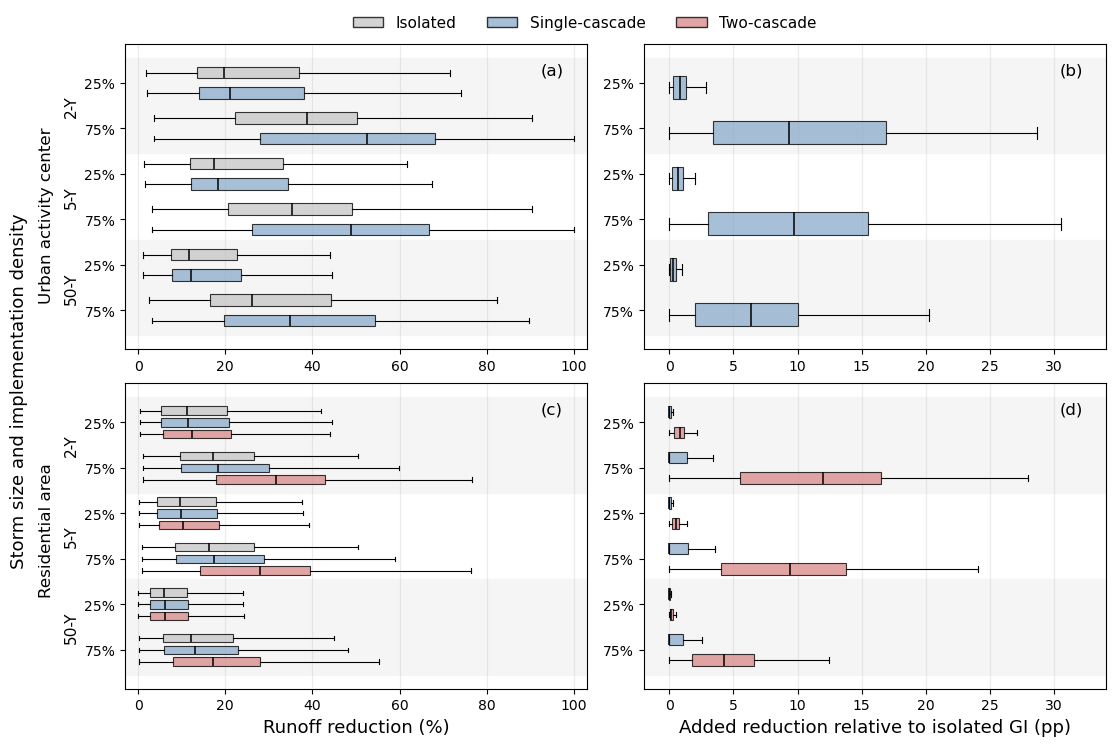

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7), constrained_layout=True, sharey=True)
fig.set_constrained_layout_pads(w_pad=0.04, h_pad=0.04, wspace=0.03, hspace=0.03)

# Data and configuration order for panels (a) to (d).
panel_data = [urban_abs_data_selected, urban_diff_data_selected,
              resi_abs_data_selected, resi_diff_data_selected]

panel_configs = [CONFIGURATIONS[:2], CONFIGURATIONS[1:2],
                 CONFIGURATIONS, CONFIGURATIONS[1:]]
row_centers = np.arange(len(row_labels_selected))[::-1]
rows_per_storm = len(densities_selected)
group_height = 0.7

for i, ax in enumerate(axes.flat):
    data = panel_data[i]
    configs = panel_configs[i]
    box_scale = 0.8 if i == 2 else 0.72
    box_height = group_height / len(configs) * box_scale
    offsets = np.linspace(-group_height / 2 + box_height / 2,
                          group_height / 2 - box_height / 2,
                          len(configs))[::-1]

    # Alternate storm backgrounds and label the left-hand panels.
    for g, storm_label in enumerate(storm_group_labels_selected):
        start = g * rows_per_storm
        end = start + rows_per_storm - 1
        if g % 2 == 0:
            ax.axhspan(row_centers[end] - 0.55, row_centers[start] + 0.55,
                       color='0.96', zorder=0)
        if i % 2 == 0:
            y_mid = (row_centers[start] + row_centers[end]) / 2
            ax.text(-0.1, y_mid, storm_label, transform=ax.get_yaxis_transform(),
                    ha='right', va='center', fontsize=11, rotation=90)


    for j, config in enumerate(configs):
        values = [np.asarray(data[row, config], dtype=float) for row in row_labels_selected]
        bp = ax.boxplot(
            values, vert=False, positions=row_centers + offsets[j],
            widths=box_height, showfliers=False, patch_artist=True, manage_ticks=False,
            medianprops={'color': 'black', 'linewidth': 1.1},
            boxprops={'linewidth': 0.8}, whiskerprops={'linewidth': 0.8},
            capprops={'linewidth': 0.8},
        )
        for patch in bp['boxes']:
            patch.set_facecolor(CONFIGURATION_COLORS[config])
            patch.set_alpha(0.78)
    ax.set_yticks(row_centers)
    ax.set_yticklabels(minor_labels_selected)
    ax.grid(axis='x', alpha=0.25)

axes[1, 0].set_xlabel('Runoff reduction (%)', fontsize=13)
axes[1, 1].set_xlabel('Added reduction relative to isolated GI (pp)', fontsize=13)

fig.text(
    -0.005,
    0.75,
    'Urban activity center',
    ha='right',
    va='center',
    fontsize=12,
    rotation=90,
)
fig.text(
    -0.005,
    0.3,
    'Residential area',
    ha='right',
    va='center',
    fontsize=12,
    rotation=90,
)

panel_letters = {(0, 0): '(a)', (0, 1): '(b)', (1, 0): '(c)', (1, 1): '(d)'}
for (i, j), letter in panel_letters.items():
    axes[i, j].text(
        0.9,
        0.94,
        letter,
        transform=axes[i, j].transAxes,
        ha='left',
        va='top',
        fontsize=12,
    )

fig.text(
    -0.03,
    0.5,
    'Storm size and implementation density',
    ha='right',
    va='center',
    fontsize=13,
    rotation=90,
)
for ax in [axes[0, 1], axes[1, 1]]:
    ax.set_yticks(np.arange(len(row_labels_selected))[::-1])
    ax.set_yticklabels(minor_labels_selected)
    ax.tick_params(axis='y', labelleft=True)
axes[0, 0].set_xlim(-3, 103)
axes[1, 0].set_xlim(-3, 103)
axes[0, 1].set_xlim(-2, 34)
axes[1, 1].set_xlim(-2, 34)
legend_labels = CONFIGURATIONS
legend_handles = [Patch(
    facecolor=CONFIGURATION_COLORS[label],
    edgecolor='black',
    alpha=0.78,
    label=label,
) for label in legend_labels]
fig.legend(
    handles=legend_handles,
    labels=legend_labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.055),
    ncol=3,
    frameon=False,
    fontsize=11,
)
plt.show()

### 1.2. Runoff variance decomposition

In [5]:
def decompose_variance(values):
    """Two-way sums of squares for configuration × matched realization (SI Eqs. S1–S3)."""
    values = np.asarray(values, dtype=float)
    values = values[:, np.isfinite(values).all(axis=0)]
    n_configs, n_valid = values.shape
    result = dict.fromkeys(['ss_total', 'ss_design', 'ss_parameter',
                            'ss_design_parameter', *share_cols], np.nan)
    result['n_valid_samples'] = n_valid
    if n_valid < 2:
        return result

    grand_mean = values.mean()
    config_mean = values.mean(axis=1)
    parameter_mean = values.mean(axis=0)
    residual = values - config_mean[:, None] - parameter_mean[None, :] + grand_mean

    ss_design = n_valid * np.sum((config_mean - grand_mean) ** 2)
    ss_parameter = n_configs * np.sum((parameter_mean - grand_mean) ** 2)
    ss_interaction = np.sum(residual ** 2)
    ss_total = np.sum((values - grand_mean) ** 2)
    result.update(ss_total=ss_total, ss_design=ss_design, ss_parameter=ss_parameter,
                  ss_design_parameter=ss_interaction)
    if ss_total > 0:
        for col, ss in zip(share_cols, (ss_design, ss_parameter, ss_interaction)):
            result[col] = 100 * ss / ss_total
    return result

def decompose_runoff(cube, nodes):
    """Apply the same decomposition separately to each subcatchment position."""
    records = []
    for k, node in enumerate(nodes):
        result = decompose_variance(cube[:, :, k])
        result['subcatchment'] = node
        records.append(result)
    return pd.DataFrame(records)

In [6]:
# decomposition summaries
variance_records = []
for spec in pair_specs:
    nodes = spec['node_idx']
    for density in DENSITY_LEVELS:
        indices = [scenario_idx[config, density] for config in spec['configs']]
        for storm_index, rp in enumerate(return_periods_all):
            cube = all_percent_reduction[storm_index, indices][:, :, nodes]
            result = decompose_runoff(cube, nodes)
            result['panel'] = spec['panel']
            result['density'] = density
            result['return_period'] = rp
            variance_records.append(result)

figS_density_pair = pd.concat(variance_records, ignore_index=True)
summary_full_decomp = (
    figS_density_pair.groupby(['panel', 'density', 'return_period'], as_index=False)[share_cols]
    .median()
)

#### Full variance-share distribution across subcatchment (Figure S12)

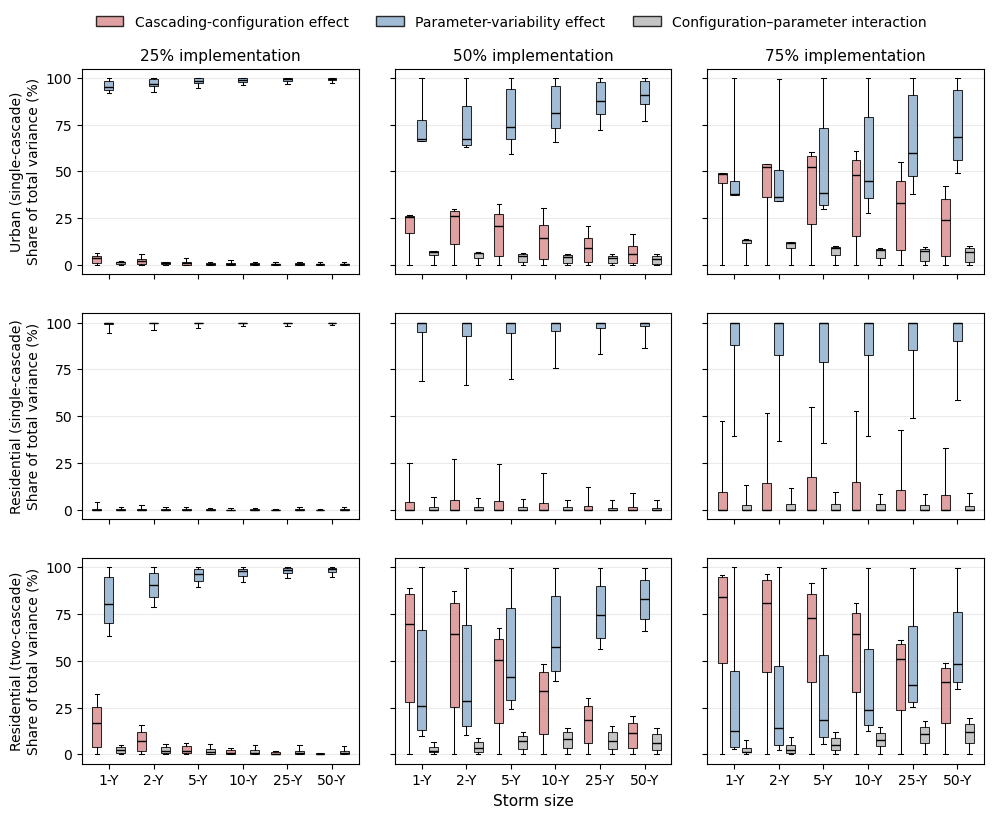

In [7]:
fig_box, axes_box = plt.subplots(3, 3, figsize=(11, 8.8), sharex=True, sharey=True)
fig_box.subplots_adjust(left=0.16, right=0.98, bottom=0.1, top=0.89, wspace=0.13, hspace=0.19)
offsets = [-0.27, 0.0, 0.27]

for i, panel in enumerate([spec['panel'] for spec in pair_specs]):
    for j, density in enumerate(DENSITY_LEVELS):
        ax = axes_box[i, j]
        sub = figS_density_pair.loc[(figS_density_pair['panel'] == panel) & (figS_density_pair['density'] == density)]
        for c, component in enumerate(share_cols):
            data_to_plot = []
            positions = []
            for k, rp in enumerate(return_periods_all):
                values = sub.loc[sub['return_period'] == rp, component].to_numpy(dtype=float)
                values = values[np.isfinite(values)]
                if len(values) > 0:
                    data_to_plot.append(values)
                    positions.append(storm_x[k] + offsets[c])
            if not data_to_plot:
                continue
            bp = ax.boxplot(
                data_to_plot,
                positions=positions,
                widths=0.2,
                patch_artist=True,
                showfliers=False,
                whis=(5, 95),
                medianprops={'color': 'black', 'linewidth': 1.0},
                boxprops={'edgecolor': 'black', 'linewidth': 0.75},
                whiskerprops={'color': 'black', 'linewidth': 0.75},
                capprops={'color': 'black', 'linewidth': 0.75},
            )
            for box in bp['boxes']:
                box.set_facecolor(component_colors[c])
                box.set_alpha(0.82)
        if i == 0:
            ax.set_title(f'{density}% implementation', fontsize=11)
        if j == 0:
            ax.set_ylabel(f"{pair_specs[i]['title']}\nShare of total variance (%)", fontsize=10)
        ax.set_xlim(-0.6, 5.6)
        ax.set_ylim(-5, 105)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.set_xticks(storm_x)
        ax.set_xticklabels(storm_labels if i == 2 else [], fontsize=10)
        ax.grid(axis='y', alpha=0.25, linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)
legend_handles = [Patch(
    facecolor=component_colors[i],
    edgecolor='black',
    alpha=0.82,
    label=component_labels[i],
) for i in range(3)]
fig_box.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.55, 0.965),
    ncol=3,
    frameon=False,
    fontsize=10,
)
axes_box[2, 1].set_xlabel('Storm size', fontsize=11)
plt.show()

#### Main analysis for median variance shares (Figure 5)

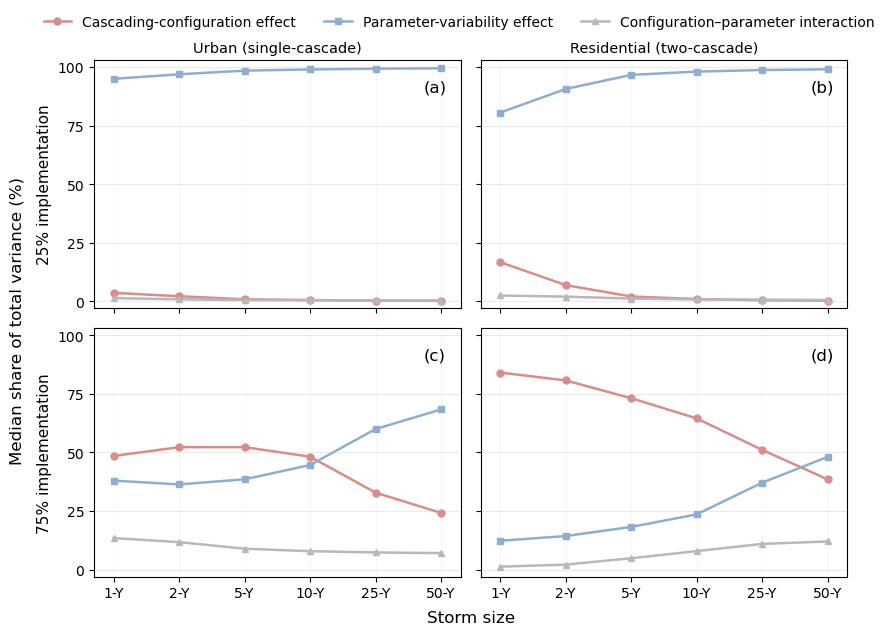

In [8]:
# urban subcatchments under the single-cascade scenario
# residiential subcatchment under the two-casade scenario

trend_specs = [pair_specs[0], pair_specs[2]]
fig_trend, axes_trend = plt.subplots(2, 2, figsize=(8.4, 6.7), sharex=True, sharey=True)
for i, density in enumerate(densities_selected):
    for j, panel in enumerate(trend_specs):
        ax = axes_trend[i, j]
        sub = summary_full_decomp.loc[(summary_full_decomp['panel'] == panel['panel']) &
            (summary_full_decomp['density'] == density)].set_index('return_period').reindex(return_periods_all)
        for c, component in enumerate(share_cols):
            ax.plot(
                storm_x + 1,
                sub[component].to_numpy(dtype=float),
                marker=markers[c],
                markersize=5,
                linewidth=1.8,
                color=component_colors[c],
                label=component_labels[c],
            )
        if i == 0:
            ax.set_title(panel['title'], fontsize=10.5)
        if j == 0:
            ax.set_ylabel(f'{density}% implementation', fontsize=11)
        ax.set_xlim(0.7, 6.3)
        ax.set_ylim(-3, 103)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.set_xticks(storm_x + 1)
        ax.set_xticklabels(storm_labels, fontsize=10)
        ax.grid(axis='y', alpha=0.25, linewidth=0.8)
        ax.grid(axis='x', alpha=0.12, linewidth=0.6)
        ax.set_axisbelow(True)
        ax.text(
            0.9,
            0.92,
            f'({chr(97 + 2 * i + j)})',
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=12,
        )
        for spine in ax.spines.values():
            spine.set_linewidth(0.8)
handles, labels = axes_trend[0, 0].get_legend_handles_labels()
fig_trend.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.52, 0.985),
    ncol=3,
    frameon=False,
    fontsize=10,
)
fig_trend.text(-0.0145, 0.3, 'Median share of total variance (%)', rotation=90, fontsize=12)
fig_trend.text(0.482, 0.06, 'Storm size', fontsize=12)
plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()

#### GSI parameter sensitivity (PRCC)

In [9]:
# load sampled parameter and re-label parameters
parameter_ensemble = pd.read_csv(DATA_DIR / 'parameter_ensemble.csv')
gr_parameters = [
    'ks_gr_cm_h',
    'porosity_gr',
    'gr_depth_cm',
    'gr_drainmat_cm',
    'field_capacity',
    'initial_moisture',
    'suction_head_cm',
]
rg_parameters = [
    'ks_rg_cm_h',
    'porosity_rg',
    'rg_depth_cm',
    'rg_berm_cm',
    'field_capacity',
    'initial_moisture',
    'suction_head_cm',
]
rb_parameters = ['rb_volume_m3', 'rb_number_per_house']
parameter_labels = {
    'ks_gr_cm_h': 'GR Ksat',
    'porosity_gr': 'GR porosity',
    'gr_depth_cm': 'GR depth',
    'gr_drainmat_cm': 'GR drainage mat',
    'ks_rg_cm_h': 'RG Ksat',
    'porosity_rg': 'RG porosity',
    'rg_depth_cm': 'RG depth',
    'rg_berm_cm': 'RG berm',
    'field_capacity': 'Field capacity',
    'initial_moisture': 'Initial moisture',
    'suction_head_cm': 'Suction head',
    'rb_volume_m3': 'RB volume',
    'rb_number_per_house': 'RB number',
}
parameter_df = parameter_ensemble.sort_values('simulation').reset_index(drop=True)

grrg_parameters = list(dict.fromkeys(gr_parameters + rg_parameters))
grrg_rb_parameters = list(dict.fromkeys(gr_parameters + rg_parameters + rb_parameters))


def calculate_prcc(response, parameter_df, parameters):
    X = parameter_df[parameters].to_numpy(dtype=float)
    Y = np.asarray(response, dtype=float)
    if Y.ndim == 1:
        Y = Y[:, None]

    X_rank = rankdata(X, axis=0)
    Y_rank = rankdata(Y, axis=0)
    constant_response = np.ptp(Y, axis=0) <= 1e-12
    records = []
    for j, parameter in enumerate(parameters):
        other_idx = [k for k in range(len(parameters)) if k != j]
        Z = np.column_stack([np.ones(len(X_rank)), X_rank[:, other_idx]])
        beta_x = np.linalg.lstsq(Z, X_rank[:, j], rcond=None)[0]
        residual_x = X_rank[:, j] - Z @ beta_x
        beta_y = np.linalg.lstsq(Z, Y_rank, rcond=None)[0]
        residual_y = Y_rank - Z @ beta_y
        numerator = np.sum(residual_x[:, None] * residual_y, axis=0)
        denominator = np.sqrt(np.sum(residual_x ** 2) * np.sum(residual_y ** 2, axis=0))
        prcc = np.divide(
            numerator,
            denominator,
            out=np.full(residual_y.shape[1], np.nan),
            where=denominator > 0,
        )
        prcc[constant_response] = np.nan
        for sub_idx_local, value in enumerate(prcc):
            records.append({'parameter': parameter, 'sub_idx_local': sub_idx_local, 'prcc': value})
    return pd.DataFrame(records)

# PRCC controls for all other parameters in the corresponding GSI scenario.
# calculate the full set once; the following three figures use different subsets.
prcc_records = []
for spec in pair_specs:
    controls = grrg_parameters if spec['landuse'] == 'Urban' else grrg_rb_parameters
    for density in DENSITY_LEVELS:
        scenario = scenario_idx[spec['configs'][1], density]
        for storm_idx, return_period in enumerate(return_periods_all):
            response = all_percent_reduction[storm_idx, scenario][:, spec['node_idx']]
            result = calculate_prcc(response, parameter_df, controls)
            result['panel'] = spec['title']
            result['density'] = density
            result['return_period'] = return_period
            result['subcatchment'] = np.asarray(spec['node_idx'])[result['sub_idx_local'].values]
            prcc_records.append(result)

prcc_results = pd.concat(prcc_records, ignore_index=True)
prcc_summary = (
    prcc_results.groupby(['panel', 'density', 'return_period', 'parameter'], as_index=False)
    ['prcc'].median().rename(columns={'prcc': 'median_prcc'})
)

prcc_panel_order = [spec['title'] for spec in pair_specs]
rb_panel_order = prcc_panel_order[1:]

In [10]:
# plot PRCC
# median acorss subcatchments for each scenario
def plot_prcc(parameters, panels, figsize, letter_y=0.84):
    fig, axes = plt.subplots(3, len(panels), figsize=figsize,
                             sharex=True, sharey=True, constrained_layout=True)
    fig.set_constrained_layout_pads(w_pad=0.035, h_pad=0.04, wspace=0.03, hspace=0.04)
    for row_i, density in enumerate(DENSITY_LEVELS):
        for col_i, panel in enumerate(panels):
            ax = axes[row_i, col_i]
            panel_data = prcc_summary[(prcc_summary['panel'] == panel) &
                                      (prcc_summary['density'] == density)]
            for parameter in parameters:
                sub = panel_data[panel_data['parameter'] == parameter].sort_values('return_period')
                ax.plot(
                    storm_x + 1,
                    sub['median_prcc'],
                    marker='o',
                    markersize=4,
                    linewidth=1.4,
                    label=parameter_labels[parameter],
                )
            ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
            ax.set_xlim(0.7, 6.3)
            ax.set_ylim(-1, 1)
            ax.set_xticks(storm_x + 1)
            ax.set_xticklabels(storm_labels, fontsize=10.5)
            ax.set_yticks([-1, -0.5, 0, 0.5, 1])
            ax.grid(axis='y', alpha=0.22, linewidth=0.8)
            ax.grid(axis='x', alpha=0.1, linewidth=0.6)
            ax.set_axisbelow(True)
            for spine in ax.spines.values():
                spine.set_linewidth(0.8)
    for col_i, panel in enumerate(panels):
        axes[0, col_i].set_title(panel, fontsize=11)
    for row_i, density in enumerate(DENSITY_LEVELS):
        axes[row_i, 0].text(
            -0.15,
            0.5,
            f'{density}% implementation',
            transform=axes[row_i, 0].transAxes,
            rotation=90,
            ha='center',
            va='center',
            fontsize=11,
        )
    fig.supylabel('Median PRCC', fontsize=12, x=-0.02)
    fig.supxlabel('Storm size', fontsize=12)
    panel_letters = [f'({chr(97 + i)})' for i in range(axes.size)]
    for ax, letter in zip(axes.flat, panel_letters):
        ax.text(0.03, letter_y, letter, transform=ax.transAxes, ha='left', va='top', fontsize=11)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc='upper center',
        bbox_to_anchor=(0.52, 1.045),
        ncol=len(parameters),
        frameon=False,
        fontsize=10,
    )
    return fig

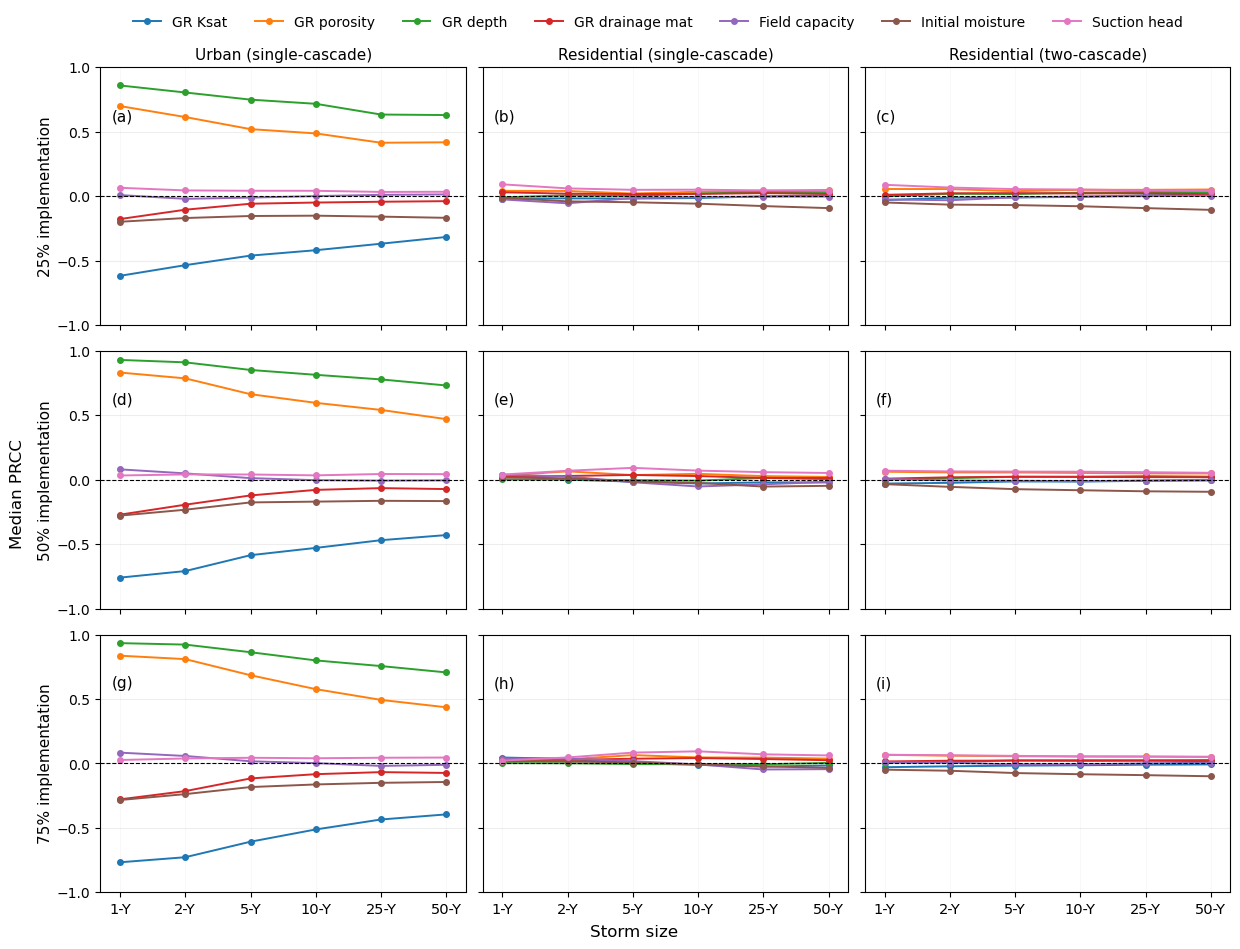

In [11]:
# green roof parameter sensitivity
fig = plot_prcc(gr_parameters, prcc_panel_order, (12, 9), letter_y=0.84)
plt.show()

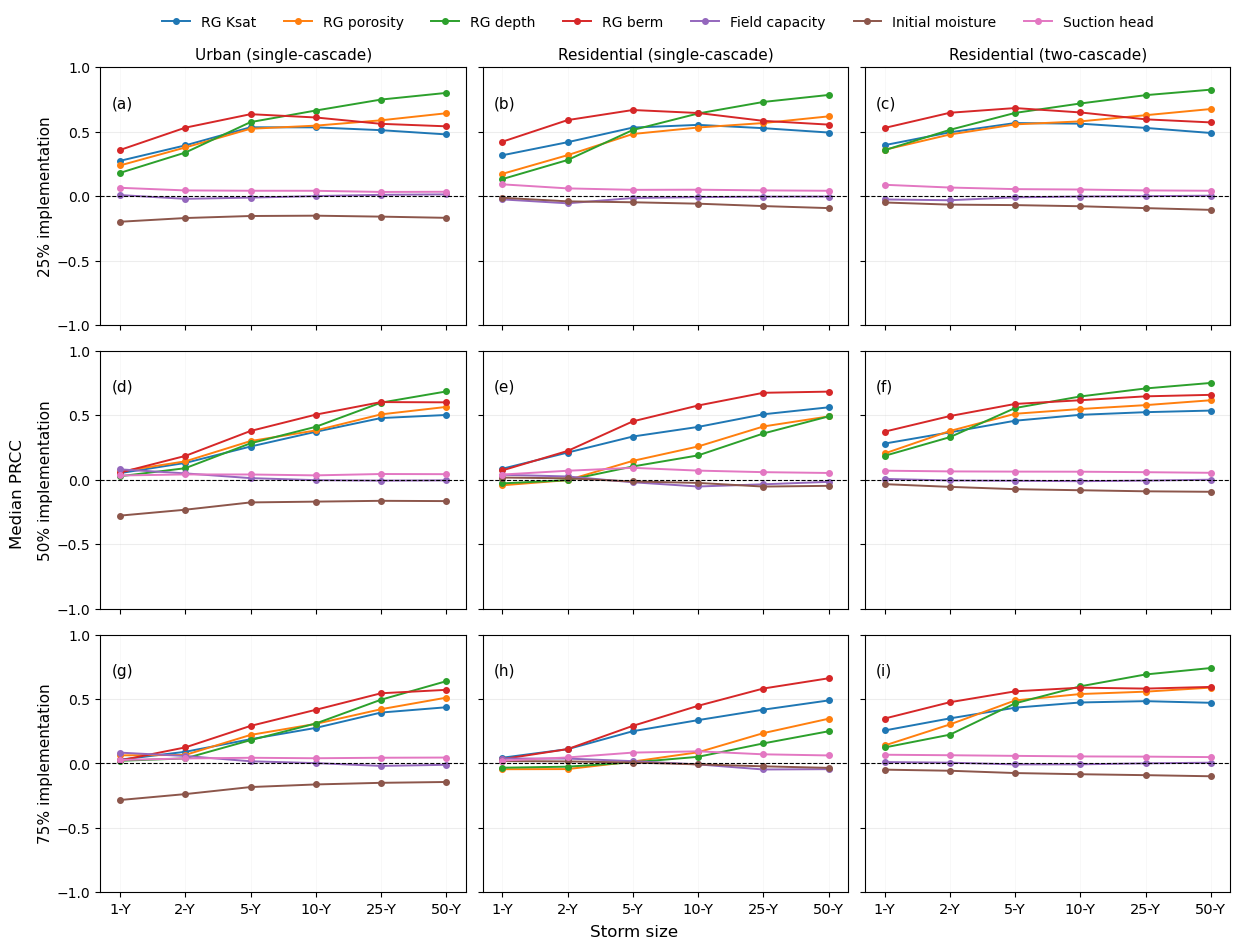

In [12]:
# rain garden parameter sensitivity
fig = plot_prcc(rg_parameters, prcc_panel_order, (12, 9), letter_y=0.89)
plt.show()

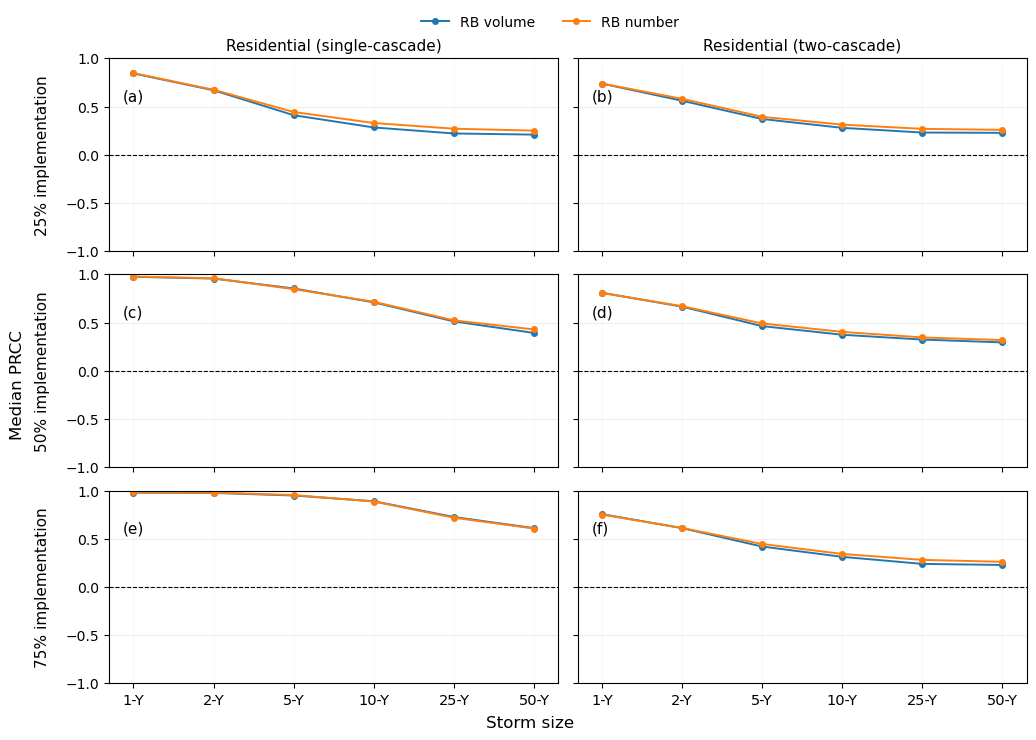

In [13]:
# rain barrel parameter sensitivity
fig = plot_prcc(rb_parameters, rb_panel_order, (10, 7), letter_y=0.84)
plt.show()

### 2. Combined sewer overflow (CSO) reduction

### 2.1. CSO reduction

In [14]:
# load CSO results
cso_reduction = pd.read_pickle(DATA_DIR / 'cso_reduction.pkl')
cso_by_storm = [cso_reduction[storm] for storm in storm_labels]

#### Overall CSO reduction distribution acorss scenarios (Figure S17)

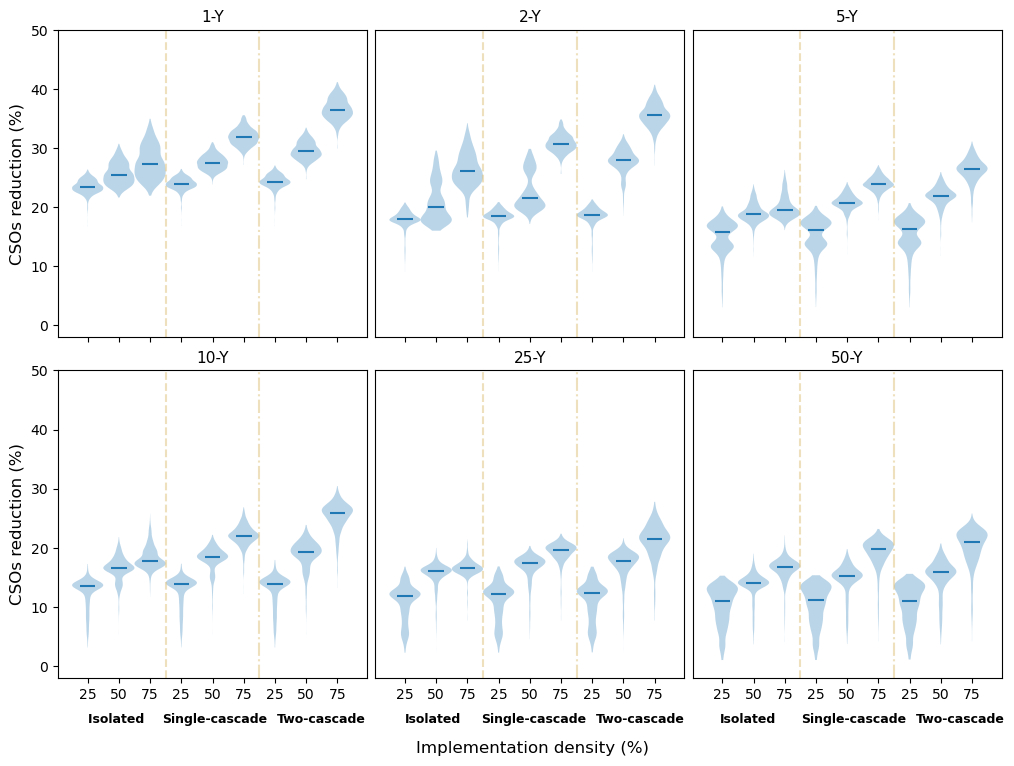

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(10, 7), constrained_layout=True)
for ax_i, values in zip(ax.flat, cso_by_storm):
    ax_i.violinplot(values, showmedians=True, widths=1, showextrema=False)
for panel_i, ax_i in enumerate(ax.flat):
    ax_i.set_title(storm_labels[panel_i], fontsize=11)
    ax_i.set_xticks(range(1, 10), list(DENSITY_LEVELS) * 3 if panel_i >= 3 else [],
                  rotation=0 if panel_i >= 3 else 45)
    ax_i.axvline(3.5, ls='--', c='#dfc27d', alpha=0.5)
    ax_i.axvline(6.5, ls='-.', c='#dfc27d', alpha=0.5)
    ax_i.set_ylim(-2, 50)
    if panel_i % 3 == 0:
        ax_i.set_ylabel('CSOs reduction (%)', fontsize=12)
    else:
        ax_i.yaxis.set_visible(False)
fig.text(0.082, -0.025, 'Isolated ', c='k', weight='bold', fontsize=9)
fig.text(0.156, -0.025, 'Single-cascade', c='k', weight='bold', fontsize=9)
fig.text(0.271, -0.025, 'Two-cascade', c='k', weight='bold', fontsize=9)
fig.text(0.399, -0.025, 'Isolated', c='k', weight='bold', fontsize=9)
fig.text(0.475, -0.025, 'Single-cascade', c='k', weight='bold', fontsize=9)
fig.text(0.59, -0.025, 'Two-cascade', c='k', weight='bold', fontsize=9)
fig.text(0.714, -0.025, 'Isolated', c='k', weight='bold', fontsize=9)
fig.text(0.795, -0.025, 'Single-cascade', c='k', weight='bold', fontsize=9)
fig.text(0.91, -0.025, 'Two-cascade', c='k', weight='bold', fontsize=9)
fig.text(0.41, -0.068, 'Implementation density (%)', c='k', fontsize=12)

plt.show()

#### Main analyses of CSO reduction and added benefit at 75% density (Figure 6)

In [16]:
# added CSO reductions 
abs_records, added_records = [], []
for rp, frame in zip(return_periods_all, cso_by_storm):
    values = np.maximum(frame.iloc[:, scenario_75].to_numpy(dtype=float), 0)
    isolated = values[:, 0]
    for i, config in enumerate(CONFIGURATIONS):
        for run_id, value in enumerate(values[:, i]):
            abs_records.append({'return_period': rp, 'run_id': run_id,
                                'scenario': config, 'cso_reduction': value})
            if i > 0:
                added_records.append({'return_period': rp, 'run_id': run_id,
                                      'comparison': config, 'added_cso_reduction': value - isolated[run_id]})

fig_cso_abs = pd.DataFrame(abs_records)
fig_cso_added = pd.DataFrame(added_records)

# summarize resutls
def summarize_cso(data, group, value):
    return data.groupby([group, 'return_period'], as_index=False).agg(
        median=(value, 'median'),
        q25=(value, lambda x: np.nanpercentile(x, 25)),
        q75=(value, lambda x: np.nanpercentile(x, 75)),
        p05=(value, lambda x: np.nanpercentile(x, 5)),
        p95=(value, lambda x: np.nanpercentile(x, 95)),
    )

summary_added = summarize_cso(fig_cso_added, 'comparison', 'added_cso_reduction')
summary_added['p_positive'] = (fig_cso_added.groupby(['comparison', 'return_period'])
                               ['added_cso_reduction'].apply(lambda x: 100 * np.mean(x > 0)).to_numpy())

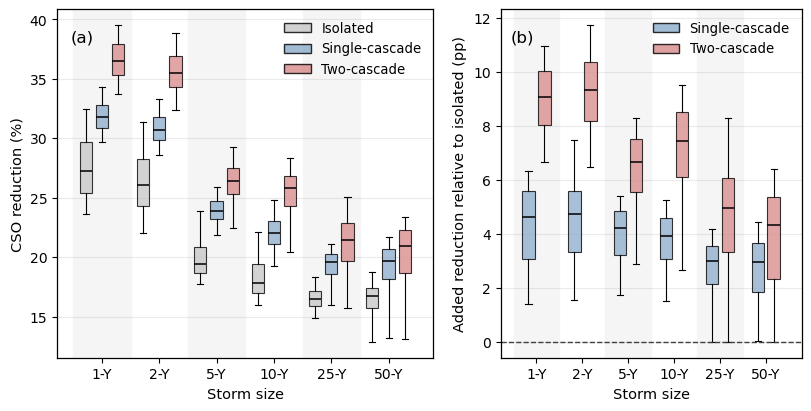

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True,
                         constrained_layout=True, gridspec_kw={'width_ratios': [1.25, 1.0]})

for i, ax in enumerate(axes):
    if i == 0:
        data = fig_cso_abs
        configs = CONFIGURATIONS
        group_col, value_col = 'scenario', 'cso_reduction'
        group_width, box_scale = 0.78, 0.82
        ylabel = 'CSO reduction (%)'
    else:
        data = fig_cso_added
        configs = CONFIGURATIONS[1:]
        group_col, value_col = 'comparison', 'added_cso_reduction'
        group_width, box_scale = 0.62, 0.88
        ylabel = 'Added reduction relative to isolated (pp)'

    for x in storm_x[::2]:
        ax.axvspan(x - 0.5, x + 0.5, color='0.96', zorder=0)

    box_width = group_width / len(configs) * box_scale
    offsets = np.linspace(-group_width / 2 + box_width / 2,
                          group_width / 2 - box_width / 2, len(configs))
    for j, config in enumerate(configs):
        subset = data[data[group_col] == config]
        values = []
        for rp in return_periods_all:
            v = subset.loc[subset['return_period'] == rp, value_col]
            values.append(v.replace([np.inf, -np.inf], np.nan).dropna().values)
        bp = ax.boxplot(
            values, positions=storm_x + offsets[j], widths=box_width,
            patch_artist=True, showfliers=False, whis=(5, 95),
            medianprops={'color': 'black', 'linewidth': 1.1},
            boxprops={'linewidth': 0.8, 'edgecolor': 'black'},
            whiskerprops={'linewidth': 0.8, 'color': 'black'},
            capprops={'linewidth': 0.8, 'color': 'black'},
        )
        for patch in bp['boxes']:
            patch.set_facecolor(CONFIGURATION_COLORS[config])
            patch.set_alpha(0.78)

    if i == 1:
        ax.axhline(0, color='0.25', linestyle='--', linewidth=1.0)
    ax.text(0.035, 0.94, ['(a)', '(b)'][i], transform=ax.transAxes,
            ha='left', va='top', fontsize=12, fontweight='normal')
    ax.set_ylabel(ylabel, fontsize=10.5)
    ax.set_xlabel('Storm size', fontsize=10.5)
    if i == 1:
        ax.set_xticks(storm_x)
        ax.set_xticklabels(storm_labels)
    ax.grid(axis='y', alpha=0.25, linewidth=0.8)
    ax.set_axisbelow(True)
    handles = [Patch(facecolor=CONFIGURATION_COLORS[config], edgecolor='black',
                     alpha=0.82, label=config) for config in configs]
    ax.legend(handles=handles, frameon=False, fontsize=9.5, loc='upper right')
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.9)

fig.get_layout_engine().set(wspace=0.05)
plt.show()

### 2.2 CSO variance decomposition (Figure 7)

In [18]:
cso_variance_records = []
for storm, frame in zip(storm_labels, cso_by_storm):
    for density in DENSITY_LEVELS:
        indices = [scenario_idx[config, density] for config in CONFIGURATIONS]
        result = decompose_variance(frame.iloc[:, indices].to_numpy(dtype=float).T)
        result.update(storm=storm, density=density)
        cso_variance_records.append(result)

cso_configuration_variance = pd.DataFrame(cso_variance_records)
cso_configuration_variance['storm'] = pd.Categorical(
    cso_configuration_variance['storm'], categories=storm_labels, ordered=True
)
cso_configuration_variance = cso_configuration_variance.sort_values(['density', 'storm']).reset_index(drop=True)
cso_configuration_variance['share_sum'] = cso_configuration_variance[share_cols].sum(axis=1, min_count=3)

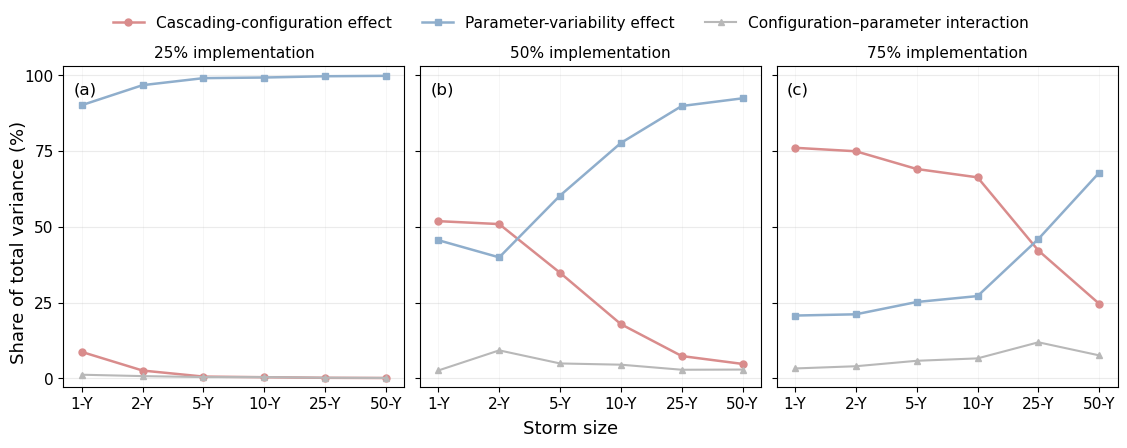

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharex=True, sharey=True, constrained_layout=True)
fig.set_constrained_layout_pads(w_pad=0.035, h_pad=0.04, wspace=0.03, hspace=0.03)
for ax, density in zip(axes, DENSITY_LEVELS):
    sub = cso_configuration_variance[cso_configuration_variance['density'] == density].sort_values('storm')
    for col, color, marker, label, width in zip(
            share_cols, component_colors, markers, component_labels, (1.8, 1.8, 1.5)):
        ax.plot(storm_x + 1, sub[col], marker=marker, markersize=5,
                color=color, linewidth=width, label=label)
    ax.set_title(f'{density}% implementation', fontsize=11)
    ax.set_xlim(0.7, 6.3)
    ax.set_xticks(storm_x + 1)
    ax.set_xticklabels(storm_labels, fontsize=11)
    ax.set_ylim(-3, 103)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_yticklabels([0, 25, 50, 75, 100], fontsize=11)
    ax.grid(axis='y', alpha=0.25, linewidth=0.8)
    ax.grid(axis='x', alpha=0.12, linewidth=0.6)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
fig.supylabel('Share of total variance (%)', fontsize=13, x=-0.01)
fig.supxlabel('Storm size', fontsize=13)
panel_letters = ['(a)', '(b)', '(c)']
for ax, letter in zip(axes, panel_letters):
    ax.text(0.03, 0.95, letter, transform=ax.transAxes, ha='left', va='top', fontsize=12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.1),
    ncol=3,
    frameon=False,
    fontsize=11,
)
plt.show()

### CSO volume (Figure S16)

In [20]:
# load simulated CSOs
hydraulic_volumes = np.load(DATA_DIR / 'cso.npz')['hydraulic_volumes']
ototal = pd.read_csv(DATA_DIR / 'baseline_cso.csv')['cso']

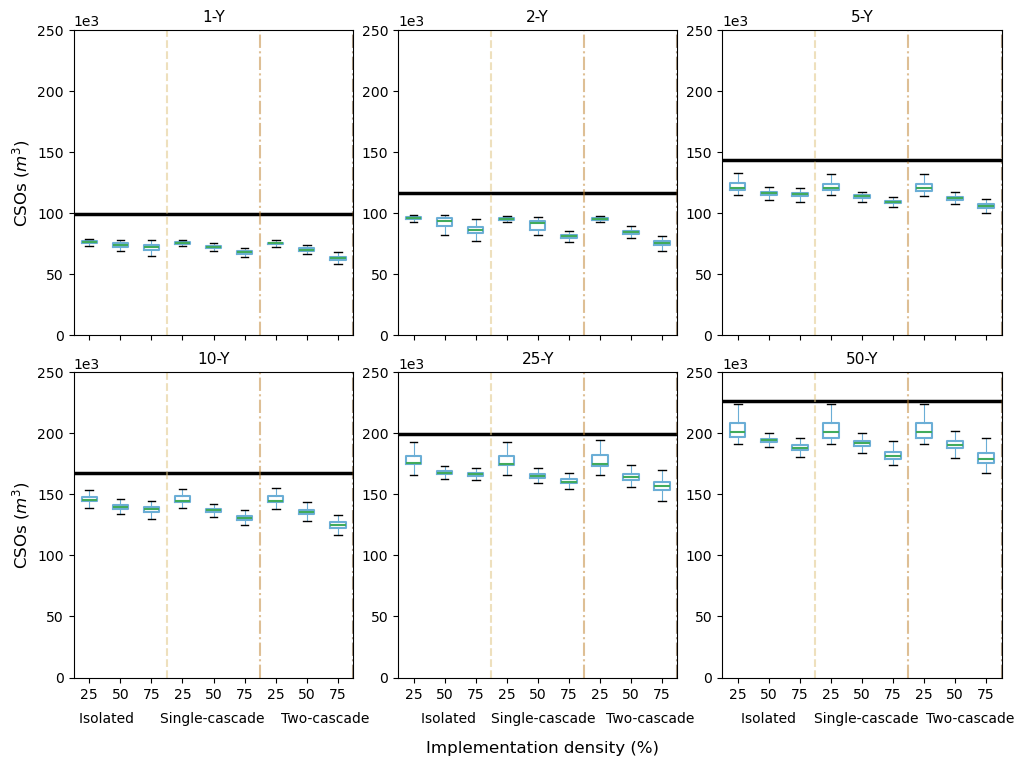

In [21]:
fig, ax = plt.subplots(2, 3, figsize=(10, 7), constrained_layout=True)

boxprops = dict(color='#6baed6', linewidth=1.5)
medianprops = dict(color='#41ab5d', linewidth=1.5)
flierprops = dict(marker='o', markersize=2)
whiskerprops = dict(linestyle='-', linewidth=0.8, color='#6baed6')

for storm_i, ax_i in enumerate(ax.flat):

    ax_i.axhline(y=ototal[storm_i], lw=2.5, c='k')

    ax_i.boxplot(
        hydraulic_volumes[storm_i].T,
        boxprops=boxprops,
        medianprops=medianprops,
        flierprops=flierprops,
        whiskerprops=whiskerprops,
        showfliers=False,
    )

    ax_i.set_title(storm_labels[storm_i], fontsize=11)
    ax_i.set_ylim(-4, 250000)
    ax_i.ticklabel_format(axis='y', style='sci', scilimits=[3, 3])

    ax_i.axvline(x=3.5, ls='--', c='#dfc27d', alpha=0.5)
    ax_i.axvline(x=6.5, ls='-.', c='#bf812d', alpha=0.5)
    ax_i.axvline(x=9.5, ls='-.', c='#543005', alpha=0.5)

# Axis labels
for ax_i in ax[0, :]:
    ax_i.set_xticks(range(1, 10), [], rotation=45)

for ax_i in ax[1, :]:
    ax_i.set_xticks(
        range(1, 10),
        ['25', '50', '75'] * 3,
        rotation=0,
    )

for ax_i in ax[:, 0]:
    ax_i.set_ylabel('CSOs ($m^3$)', fontsize=12)

# Configuration labels
for positions in [
    [0.073, 0.154, 0.275],
    [0.415, 0.485, 0.600],
    [0.735, 0.808, 0.920]
]:
    for x, label in zip(positions, CONFIGURATIONS):
        fig.text(x, -0.025, label + ' ', c='k')

fig.text(0.42, -0.068, 'Implementation density (%)', c='k', fontsize=12)
plt.show()

### Total runoff volume by land use (Figure S11)

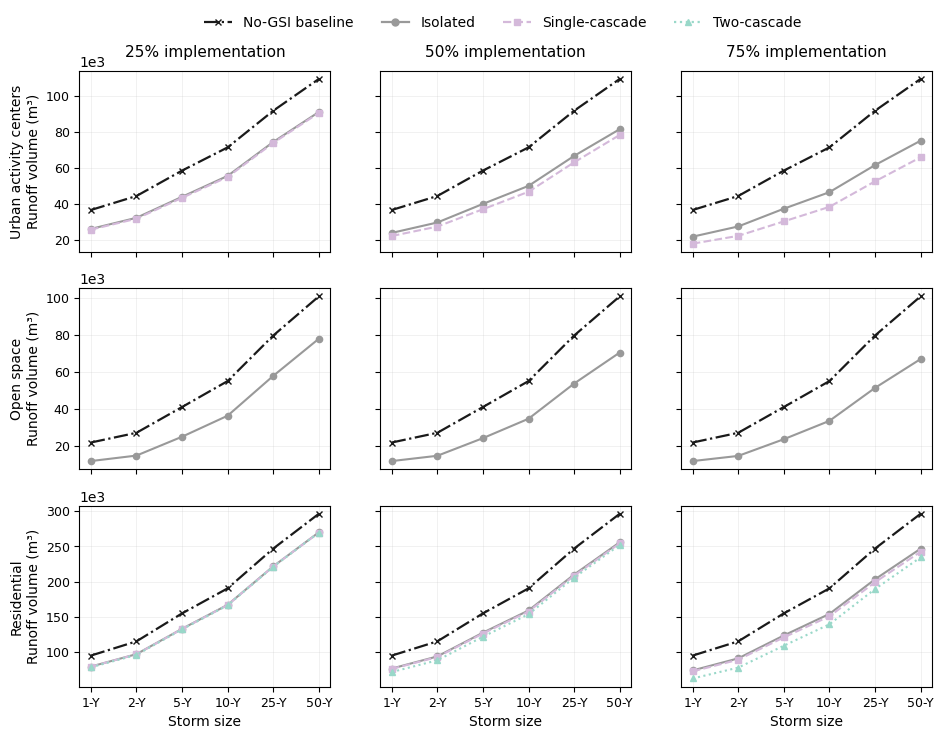

In [22]:
# load simulated results
runoff_volume = pd.read_csv(DATA_DIR / 'absulate flow.csv')
# convert units to m3
GAL_MILLION_TO_M3 = 3785.411784
land_uses = ['Urban activity centers', 'Open space', 'Residential']
allowed = {
    'Urban activity centers': ['Isolated', 'Single-cascade (GR-RG)'],
    'Open space': ['Isolated'],
    'Residential': ['Isolated', 'Single-cascade (GR-RG)', 'Two-cascade'],
}
styles = {
    'No-GSI baseline': dict(color='#1a1a1a', marker='x', linestyle='-.'),
    'Isolated': dict(color='0.6', marker='o', linestyle='-'),
    'Single-cascade (GR-RG)': dict(color='#d4b9da', marker='s', linestyle='--'),
    'Two-cascade': dict(color='#99d8c9', marker='^', linestyle=':'),
}
fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharex=True, sharey='row')
for r, land_use in enumerate(land_uses):
    base = runoff_volume[(runoff_volume.land_use == land_use) & (runoff_volume.configuration == 'No-GSI baseline')].sort_values('storm_years')
    for c, density in enumerate(DENSITY_LEVELS):
        ax = axes[r, c]
        ax.plot(
            storm_x + 1,
            base.baseline_million_gal * GAL_MILLION_TO_M3,
            linewidth=1.6,
            markersize=5,
            zorder=5,
            **styles['No-GSI baseline'],
        )
        subset = runoff_volume[(runoff_volume.land_use == land_use) & (runoff_volume.implementation_density_pct == density)]
        for config in allowed[land_use]:
            s = subset[subset.configuration == config].sort_values('storm_years')
            ax.plot(
                storm_x + 1,
                s.inflow_median_million_gal * GAL_MILLION_TO_M3,
                linewidth=1.5,
                markersize=4.5,
                **styles[config],
            )
        ax.set_xticks(storm_x + 1, storm_labels)
        ax.grid(alpha=0.2, linewidth=0.6)
        ax.tick_params(labelsize=9)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
        if r == 0:
            ax.set_title(f'{density}% implementation', fontsize=11, pad=10)
        if c == 0:
            ax.set_ylabel(f'{land_use}\nRunoff volume (m³)', fontsize=10)
        if r == 2:
            ax.set_xlabel('Storm size', fontsize=10)
legend_names = {
    'No-GSI baseline': 'No-GSI baseline',
    'Isolated': 'Isolated',
    'Single-cascade (GR-RG)': 'Single-cascade',
    'Two-cascade': 'Two-cascade',
}
handles = [Line2D(
    [0],
    [0],
    linewidth=1.6,
    markersize=5,
    label=legend_names[k],
    **styles[k],
) for k in styles]
fig.legend(
    handles=handles,
    loc='lower center',
    bbox_to_anchor=(0.51, 0.916),
    ncol=4,
    frameon=False,
    fontsize=10,
)
plt.show()

### Sensitivity to the contributing impervious area

The 1:1, 3:1, and 5:1 loading ratios are compared at 75% implementation density. Use the same realization order and scenario order (3, 6, 9) for every ratio. 

In [23]:
sensitivity_runoff = {}
sensitivity_simulation = {}
for ratio in LOADING_RATIOS:
    with np.load(DATA_DIR / f'run_reduction{ratio}.npz') as data:
        sensitivity_runoff[ratio] = data['percent_reduction']
        sensitivity_simulation[ratio] = (
            data['simulation'] if 'simulation' in data else np.arange(sensitivity_runoff[ratio].shape[2])
        )

sensitivity_cso = {
    ratio: pd.read_pickle(DATA_DIR/ f'cso_reduction{ratio}.pkl')
    for ratio in LOADING_RATIOS
}
sensitivity_config_idx = {config: i for i, config in enumerate(CONFIGURATIONS)}


for storm in storm_labels:
    for ratio in LOADING_RATIOS:
        frame = sensitivity_cso[ratio][storm]

In [24]:
def sensitivity_runoff_boxes(storm_index, configuration, nodes):
    config_index = sensitivity_config_idx[configuration]
    isolated_index = sensitivity_config_idx['Isolated']

    added_by_ratio = {
        ratio: (
            sensitivity_runoff[ratio][storm_index, config_index][:, nodes]
            - sensitivity_runoff[ratio][storm_index, isolated_index][:, nodes]
        )
        for ratio in LOADING_RATIOS
    }

    common_subcatchments = np.logical_and.reduce([
        np.isfinite(values).any(axis=0)
        for values in added_by_ratio.values()
    ])

    # Mean across simulations; boxplot across subcatchments.
    return {
        ratio: np.nanmean(values[:, common_subcatchments], axis=0)
        for ratio, values in added_by_ratio.items()
    }


def sensitivity_cso_boxes(storm, configuration):
    config_index = sensitivity_config_idx[configuration]
    isolated_index = sensitivity_config_idx['Isolated']
    added_by_ratio = {}

    for ratio in LOADING_RATIOS:
        storm_data = sensitivity_cso[ratio][storm]
        isolated = storm_data.iloc[:, isolated_index].to_numpy(dtype=float)
        cascading = storm_data.iloc[:, config_index].to_numpy(dtype=float)
        added_by_ratio[ratio] = cascading - isolated

    return added_by_ratio

def draw_loading_ratio_boxes(ax, values_by_ratio, storm_index):
    for ratio in LOADING_RATIOS:
        values = np.asarray(values_by_ratio[ratio], dtype=float)
        values = values[np.isfinite(values)]

        if values.size == 0:
            continue

        ax.boxplot(
            [values],
            positions=[storm_x[storm_index] + ratio_offsets[ratio]],
            widths=box_width,
            patch_artist=True,
            showfliers=False,
            medianprops={'color': 'black', 'linewidth': 1.2},
            boxprops={
                'facecolor': ratio_facecolors[ratio],
                'edgecolor': 'black',
                'linewidth': 0.8,
            },
            whiskerprops={'color': 'black', 'linewidth': 0.8},
            capprops={'color': 'black', 'linewidth': 0.8},
        )

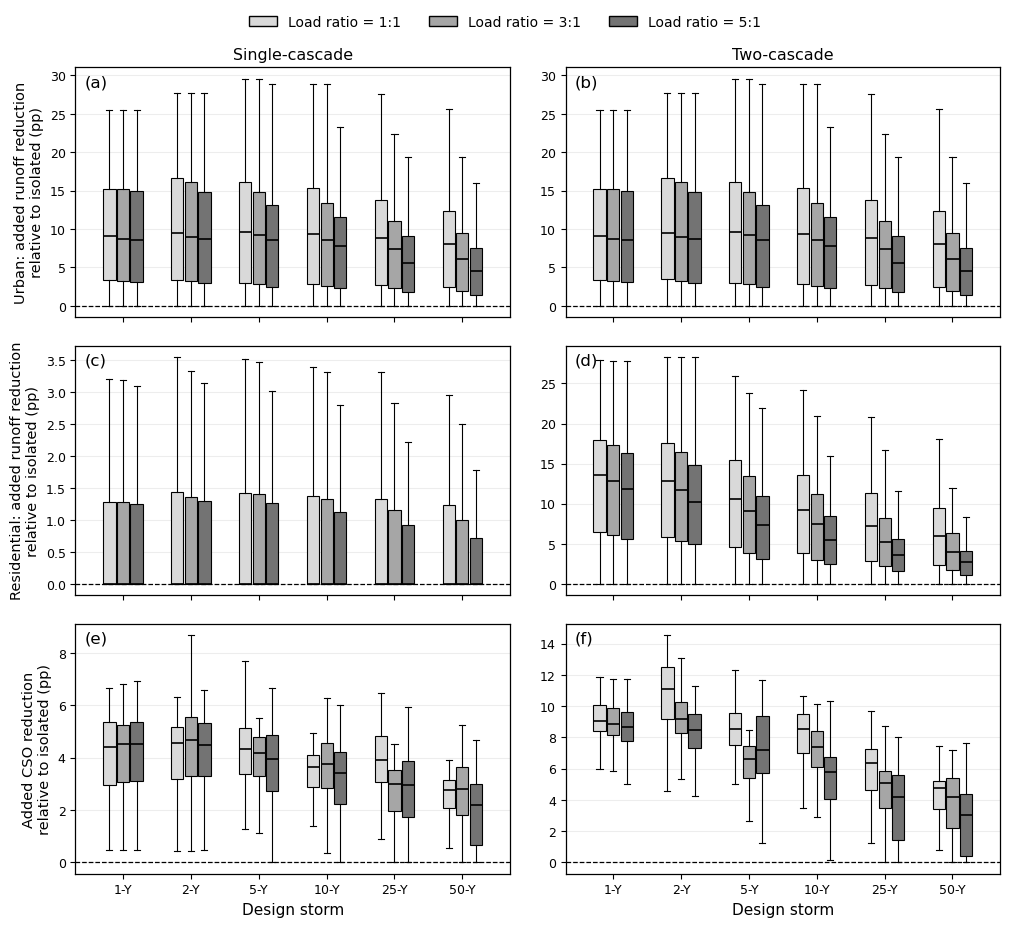

In [25]:
# Plot settings
ratio_offsets = {1: -0.20, 3: 0.00, 5: 0.20}
ratio_facecolors = {1: '0.85', 3: '0.65', 5: '0.45'}
box_width = 0.18
storm_x = np.arange(len(storm_labels))

fig, axes = plt.subplots(
    3, 2, figsize=(10.0, 8.8),
    sharex=True, constrained_layout=True
)

fig.set_constrained_layout_pads(
    w_pad=0.05, h_pad=0.05,
    wspace=0.06, hspace=0.08
)

for column, configuration in enumerate(CONFIGURATIONS[1:]):

    urban_ax = axes[0, column]
    resi_ax = axes[1, column]
    cso_ax = axes[2, column]

    for storm_index, storm in enumerate(storm_labels):

        # Row 1: Urban runoff
        draw_loading_ratio_boxes(
            urban_ax,
            sensitivity_runoff_boxes(
                storm_index, configuration, urban_idx
            ),
            storm_index,
        )

        # Row 2: Residential runoff
        draw_loading_ratio_boxes(
            resi_ax,
            sensitivity_runoff_boxes(
                storm_index, configuration, resi_idx
            ),
            storm_index,
        )

        # Row 3: Sewershed CSO
        draw_loading_ratio_boxes(
            cso_ax,
            sensitivity_cso_boxes(storm, configuration),
            storm_index,
        )

    for ax in (urban_ax, resi_ax, cso_ax):
        ax.axhline(
            0, color='black',
            linestyle='--', linewidth=0.9
        )

    urban_ax.set_title(configuration, fontsize=11.5)


# Axis labels
axes[0, 0].set_ylabel(
    'Urban: added runoff reduction\nrelative to isolated (pp)',
    fontsize=10.5
)

axes[1, 0].set_ylabel(
    'Residential: added runoff reduction\nrelative to isolated (pp)',
    fontsize=10.5
)

axes[2, 0].set_ylabel(
    'Added CSO reduction\nrelative to isolated (pp)',
    fontsize=10.5
)


# Formatting
for ax in axes.ravel():
    ax.set_xticks(storm_x)
    ax.set_xticklabels(storm_labels, fontsize=9)
    ax.grid(axis='y', alpha=0.22)
    ax.tick_params(axis='y', labelsize=9)

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)


axes[-1,1].set_xlabel('Design storm', fontsize=11)
axes[-1,0].set_xlabel('Design storm', fontsize=11)

# Legend
fig.legend(
    handles=[
        Patch(
            facecolor=ratio_facecolors[ratio],
            edgecolor='black',
            label=f'Load ratio = {ratio}:1'
        )
        for ratio in LOADING_RATIOS
    ],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.045),
    ncol=3,
    frameon=False,
    fontsize=10,
)


# Panel letters
for ax, label in zip(
    axes.ravel(),
    ('(a)', '(b)', '(c)', '(d)', '(e)', '(f)')
):
    ax.text(
        0.02, 0.97, label,
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=12,
    )
plt.show()

In [26]:
# Compare the same two runoff pairs as the main-text trend figure.
sensitivity_pair_specs = trend_specs
sensitivity_runoff_records = []
for spec in sensitivity_pair_specs:
    nodes = spec['node_idx']
    indices = [sensitivity_config_idx[config] for config in spec['configs']]
    for storm_index, rp in enumerate(return_periods_all):
        cubes = {}
        for ratio in LOADING_RATIOS:
            cubes[ratio] = sensitivity_runoff[ratio][storm_index, indices][:, :, nodes]

        # Use the same complete realizations at every ratio, separately for each node.
        common_samples = np.ones(cubes[LOADING_RATIOS[0]].shape[1:], dtype=bool)
        for cube in cubes.values():
            common_samples &= np.isfinite(cube).all(axis=0)

        decompositions = {}
        common_nodes = np.ones(len(nodes), dtype=bool)
        for ratio, cube in cubes.items():
            matched_cube = np.where(common_samples[None, :, :], cube, np.nan)
            result = decompose_runoff(matched_cube, nodes)
            decompositions[ratio] = result
            common_nodes &= np.isfinite(result[share_cols]).all(axis=1).to_numpy()

        # Summarize nodes with defined shares at every ratio.
        for ratio, result in decompositions.items():
            result['panel'] = spec['panel']
            result['return_period'] = rp
            result['loading_ratio'] = ratio
            result['included_in_summary'] = common_nodes
            sensitivity_runoff_records.append(result)

sensitivity_runoff_variance = pd.concat(sensitivity_runoff_records, ignore_index=True)
sensitivity_runoff_summary = (
    sensitivity_runoff_variance.loc[sensitivity_runoff_variance['included_in_summary']]
    .groupby(['panel', 'return_period', 'loading_ratio'], as_index=False)
    .agg(design_share_total=('design_share_total', 'median'),
         parameter_share_total=('parameter_share_total', 'median'),
         dependence_share_total=('dependence_share_total', 'median'),
         n_valid_subcatchments=('subcatchment', 'size'),
         min_valid_samples=('n_valid_samples', 'min'))
)

In [27]:
sensitivity_cso_records = []
for rp, storm in zip(return_periods_all, storm_labels):
    matrices = {
        ratio: sensitivity_cso[ratio][storm].to_numpy(dtype=float).T
        for ratio in LOADING_RATIOS
    }
    common_samples = np.logical_and.reduce([np.isfinite(matrix).all(axis=0)
                                            for matrix in matrices.values()])
    for ratio, matrix in matrices.items():
        result = decompose_variance(matrix[:, common_samples])
        result.update(panel='CSO', return_period=rp, loading_ratio=ratio)
        sensitivity_cso_records.append(result)

sensitivity_cso_variance = pd.DataFrame(sensitivity_cso_records)
sensitivity_variance_summary = pd.concat(
    [sensitivity_runoff_summary, sensitivity_cso_variance], ignore_index=True
)

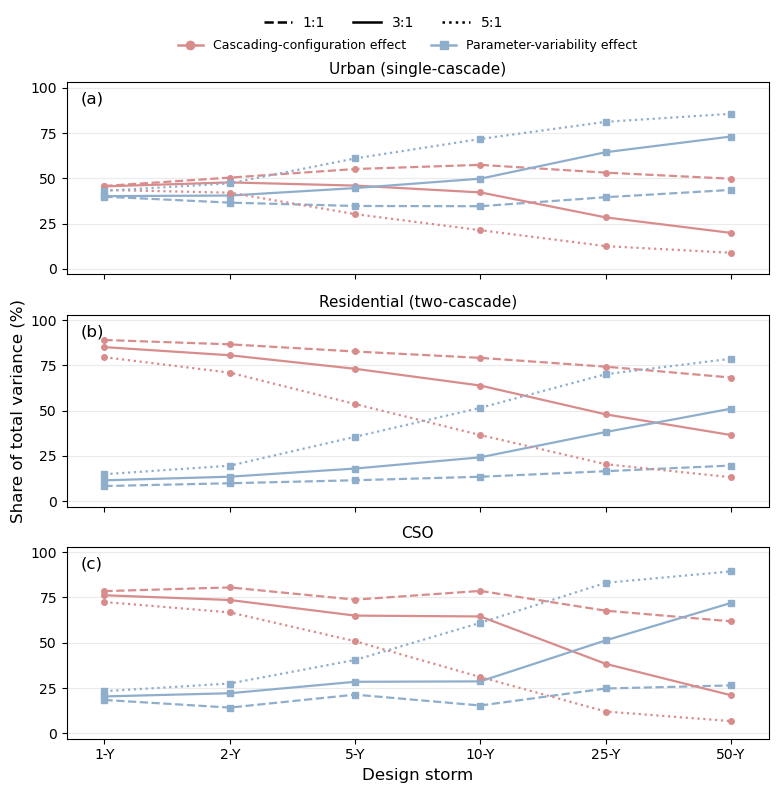

In [28]:
# Three panels: two runoff comparisons and the sewershed-scale CSO comparison.
# The interaction share is calculated but not plotted.

# Line styles distinguish the loading ratios.
ratio_linestyles = {1: '--', 3: '-', 5: ':'}
sensitivity_variance_panels = [spec['panel'] for spec in sensitivity_pair_specs] + ['CSO']
sensitivity_variance_titles = [spec['title'] for spec in sensitivity_pair_specs] + ['CSO']

fig_sensitivity_variance, axes_sensitivity_variance = plt.subplots(
    3, 1, figsize=(8.0, 8.8), sharex=True, sharey=True
)

for i, (ax, panel, title) in enumerate(zip(
        axes_sensitivity_variance, sensitivity_variance_panels, sensitivity_variance_titles)):
    for ratio in LOADING_RATIOS:
        sub = sensitivity_variance_summary.loc[
            (sensitivity_variance_summary['panel'] == panel)
            & (sensitivity_variance_summary['loading_ratio'] == ratio)
        ].set_index('return_period').reindex(return_periods_all)

        for component, color, marker in zip(share_cols[:2], component_colors[:2], markers[:2]):
            ax.plot(
                storm_x, sub[component], color=color,
                linestyle=ratio_linestyles[ratio], marker=marker,
                markersize=4, linewidth=1.6,
            )

    ax.set_title(title, fontsize=11)
    ax.text(0.02, 0.95, f'({chr(97 + i)})', transform=ax.transAxes,
            ha='left', va='top', fontsize=12)
    ax.set_xlim(-0.3, len(storm_labels) - 0.7)
    ax.set_ylim(-3, 103)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_xticks(storm_x)
    ax.grid(axis='y', alpha=0.25, linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

axes_sensitivity_variance[-1].set_xticklabels(storm_labels, fontsize=10)

# Separate legends distinguish the two main effects and three loading ratios.
component_handles = [
    Line2D([0], [0], color=color, marker=marker, linewidth=1.8, label=label)
    for color, marker, label in zip(component_colors[:2], markers[:2], component_labels[:2])
]
ratio_handles = [
    Line2D([0], [0], color='black', linestyle=ratio_linestyles[ratio],
           linewidth=1.8, label=f'{ratio}:1')
    for ratio in LOADING_RATIOS
]

fig_sensitivity_variance.legend(
    handles=component_handles, loc='upper center', bbox_to_anchor=(0.53, 0.892),
    ncol=2, frameon=False, fontsize=9,
)
fig_sensitivity_variance.legend(
    handles=ratio_handles,  loc='upper center',
    bbox_to_anchor=(0.5, 0.92), ncol=3, frameon=False, fontsize=10,
)
fig_sensitivity_variance.tight_layout(rect=[0.04, 0.04, 1, 0.87])
axes_sensitivity_variance[1].set_ylabel('Share of total variance (%)', fontsize=12)
axes_sensitivity_variance[2].set_xlabel('Design storm', fontsize=12)

plt.show()

### GSI implementation and suitable areas

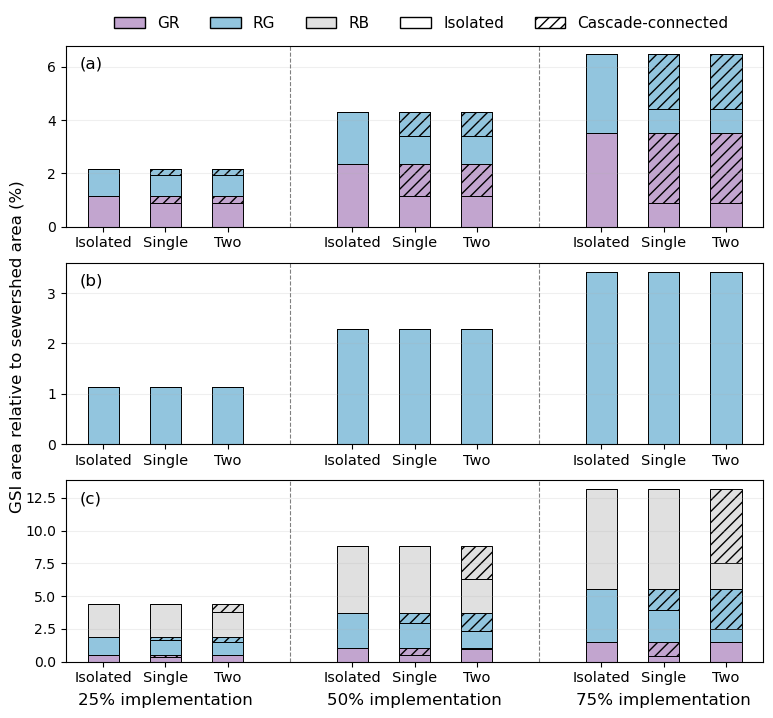

In [29]:
# Implemented GSI areas relative to sewershed area (Figure 3)
gsi_area_summary = pd.read_csv(DATA_DIR / 'data_percent.csv')

area_configs_label = ['Isolated', 'Single', 'Two']

x = np.array([0, 1, 2, 4, 5, 6, 8, 9, 10])

fig, axes = plt.subplots(
    3, 1, figsize=(9, 8), sharex=True
)

for i, landuse in enumerate(LAND_USES):

    ax = axes[i]

    sub = gsi_area_summary[gsi_area_summary["Land use"] == landuse]
    sub = sub.set_index(["Density", "Configuration"])
    sub = sub.loc[
        [(d, c) for d in DENSITY_LEVELS for c in CONFIGURATIONS]
    ]

    bottom = np.zeros(9)

    for gsi in GSI_TYPES:
        for route, hatch in [("iso", ""), ("cas", "///")]:

            values = sub[f"{gsi}_{route}"].to_numpy()

            ax.bar(
                x, values,
                bottom=bottom,
                width=0.5,
                color=GSI_COLORS[gsi],
                edgecolor="black",
                linewidth=0.7,
                hatch=hatch
            )

            bottom += values

    ax.text(
        0.02, 0.94,
        f"({chr(97+i)})",
        transform=ax.transAxes,
        fontsize=12,
        va="top"
    )

    for separator in [3, 7]:
        ax.axvline(
            separator, color="gray",
            linestyle="--", linewidth=0.8
        )
    ax.set_ylim(0, bottom.max() * 1.05)
    ax.set_xlim(-0.6, 10.6)
    ax.grid(axis="y", alpha=0.2)

    ax.set_xticks(x)
    ax.set_xticklabels(area_configs_label * 3, fontsize = 10.5)
    ax.tick_params(axis="x", labelbottom=True)
for j, density in enumerate(DENSITY_LEVELS):
    axes[-1].text(
        x[j*3+1], -0.24,
        f"{density}% implementation",
        transform=axes[-1].get_xaxis_transform(),
        ha="center", fontsize=12
    )

gsi_legend = [
    Patch(facecolor=GSI_COLORS[g], edgecolor="black", label=g)
    for g in GSI_TYPES
]

routing_legend = [
    Patch(facecolor="white", edgecolor="black", label="Isolated"),
    Patch(facecolor="white", edgecolor="black",
          hatch="///", label="Cascade-connected")
]

fig.legend(
    handles=gsi_legend + routing_legend,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.52, 0.934),
    fontsize = 11
)
fig.text(0.063, 0.3, "GSI area relative to sewershed area (%)", rotation = 90, fontsize=12)
plt.show()

### Distribution of suitable GSI areas by land use

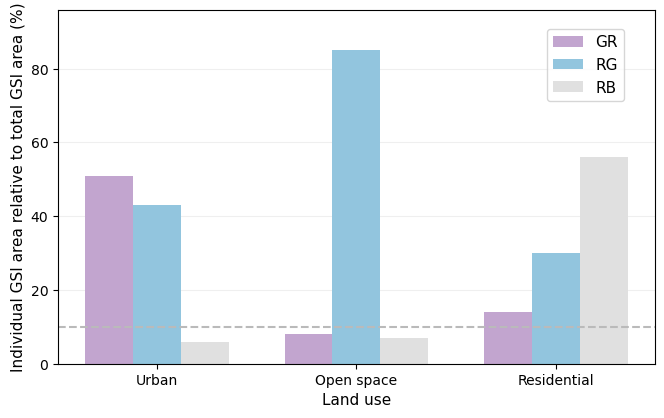

In [30]:
gsi_potential_summary = pd.read_csv(DATA_DIR / 'summary_by_landuse.csv')
x = np.arange(3)
width = 0.24
fig, ax = plt.subplots(figsize=(7.7, 4.6))

for i, gist in enumerate(GSI_TYPES):
    values = (gsi_potential_summary[gsi_potential_summary["GI"] == gist]
              .set_index("Land_use").loc[list(LAND_USES), "Share_within_landuse_pct"].values)
    bars = ax.bar(x + (i-1)*width, values, width=width, label=gist, color=GSI_COLORS[gist])

ax.axhline(10, linestyle = '--', c = '#bababa')
ax.set_xticks(x, LAND_USES)
ax.set_ylabel("Individual GSI area relative to total GSI area (%)", fontsize = 11)
ax.set_xlabel("Land use", fontsize = 11)
ax.set_ylim(0, 96)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

gsi_legend = [
    Patch(facecolor=GSI_COLORS[g],  label=g)
    for g in GSI_TYPES
]

fig.legend(
    handles=gsi_legend ,
    ncol=1,
    frameon=True,
    bbox_to_anchor=(0.87, 0.855),
    fontsize = 11
)
plt.show()

### Implemented GSI areas within subcatchments

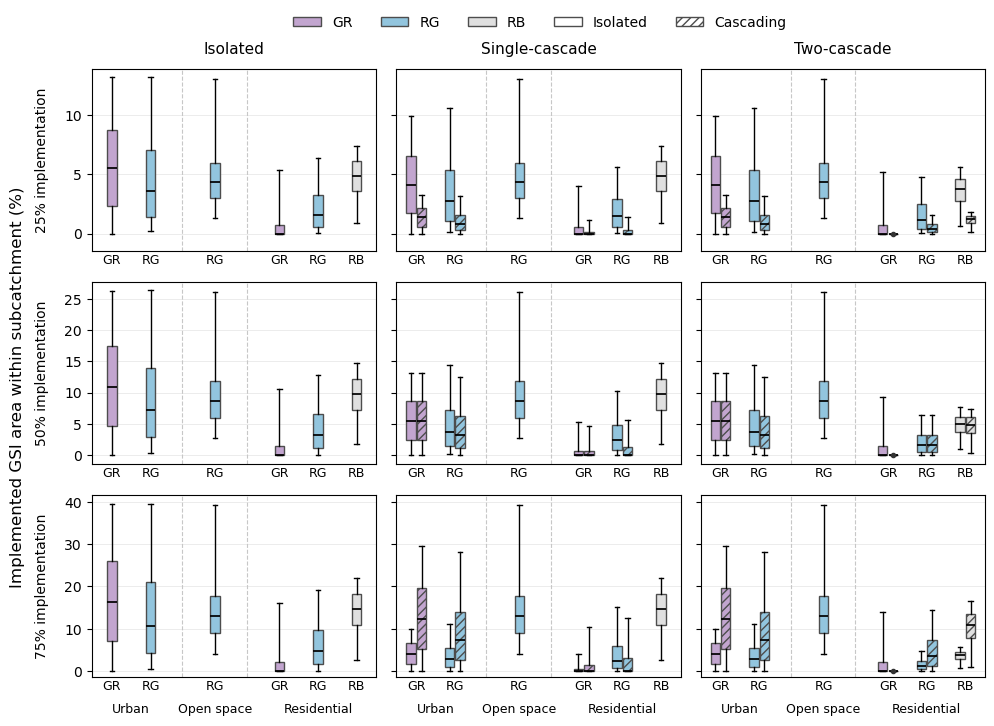

In [31]:
gsi_implementation = pd.read_csv(DATA_DIR / 'sub_percent.csv')
categories = [
    ('Urban', 'GR', 0),
    ('Urban', 'RG', 1.2),
    ('Open space', 'RG', 3.2),
    ('Residential', 'GR', 5.2),
    ('Residential', 'RG', 6.4),
    ('Residential', 'RB', 7.6),
]

fig, axes = plt.subplots(3, 3, figsize=(10, 8), sharex=True, sharey='row')

for i, density in enumerate(DENSITY_LEVELS):
    for j, config in enumerate(CONFIGURATIONS):
        ax = axes[i, j]
        scenario = gsi_implementation.loc[
            (gsi_implementation['Density_pct'] == density) &
            (gsi_implementation['Configuration'] == config)
        ]

        for landuse, gi, center in categories:
            local = scenario.loc[scenario['Land_use'] == landuse]

            # Each plotted box must retain zeros for the ENTIRE land-use set.
            boxes = []
            for status in ['iso', 'cas']:
                values_all = local[f'{gi}_{status}_pct'].to_numpy(dtype=float)
                n_positive = int(np.count_nonzero(values_all > 0))

                if n_positive > 0:
                    boxes.append((status, values_all))

            for k, (status, values) in enumerate(boxes):
                x = center + (k - (len(boxes) - 1) / 2) * 0.33
                bp = ax.boxplot(
                    values,
                    positions=[x],
                    widths=0.29,
                    patch_artist=True,
                    whis=(5, 95),
                    showfliers=False,
                    medianprops={'color': 'black', 'linewidth': 1.25},
                )
                bp['boxes'][0].set_facecolor(GSI_COLORS[gi])
                bp['boxes'][0].set_edgecolor('0.3')
                if status == 'cas':
                    bp['boxes'][0].set_hatch('////')
                if np.percentile(values, 95) == 0:
                    ax.plot(x, 0, marker='o', markersize=3,
                            color='0.2', zorder=6)

        for x in [2.18, 4.18]:
            ax.axvline(x, color='0.78', linestyle='--', linewidth=0.8)
        ax.set_xlim(-0.62, 8.21)
        ax.set_ylim(bottom=-1.5)
        ax.set_xticks([c[2] for c in categories])
        ax.set_xticklabels([c[1] for c in categories], fontsize=9)
        ax.tick_params(axis='x', length=0, labelbottom=True, pad=2)
        ax.grid(axis='y', color='0.88', linewidth=0.65, alpha=0.65)
        ax.set_axisbelow(True)

        if i == 0:
            ax.set_title(config, fontsize=11, pad=11)
        if j == 0:
            ax.text(-0.175, 0.5, f'{density}% implementation',
                    rotation=90, ha='center', va='center',
                    transform=ax.transAxes, fontsize=10)

for ax in (axes[2,0],axes[2,1],axes[2,2]):
    for x, label in [(0.6, 'Urban'), (3.2, 'Open space'), (6.4, 'Residential')]:
        ax.text(x, -0.14, label,
                transform=ax.get_xaxis_transform(), ha='center',
                va='top', fontsize=9, clip_on=False)

fig.supylabel('Implemented GSI area within subcatchment (%)', x=0.01)
legend = [Patch(facecolor=GSI_COLORS[gi], edgecolor='0.3', label=gi)
          for gi in GSI_TYPES]
legend += [
    Patch(facecolor='white', edgecolor='0.3', label='Isolated'),
    Patch(facecolor='white', edgecolor='0.3', hatch='////', label='Cascading'),
]
fig.legend(handles=legend, loc='upper center', bbox_to_anchor=(0.54, 0.98),
           ncol=5, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()